# Predicting Internet Access to Plan Digital Education in East Africa
**Author:** Andrew Thon Riem Alier

**Mission link.** My mission is to use technology to fight digital illiteracy and poor access to digital resources in South Sudan and East Africa. Online learning, e-libraries and online applications for national and academic documents only help people who can actually get online.

**Use case.** The model predicts the **percentage of a country's population using the internet** from its infrastructure, economic, education and governance indicators.
* **Who uses it:** South Sudan's Ministry of General Education, East African education ministries (Kenya, Uganda, Tanzania, Rwanda, Burundi, Ethiopia) and the NGOs that run digital-learning programmes there.
* **What for:** (1) deciding whether a learning or document service should be delivered **online or offline** (radio, SMS, preloaded tablets, community hubs), and (2) finding countries whose internet use is **lower than their electricity and income would predict**, which means the barrier is cost, skills or conflict, so digital-literacy training should be planned there first.

**Why train on all countries?** East Africa alone has only about 136 complete rows (South Sudan has 3), too few to train reliable models. The model learns the general relationships from about 190 countries, and Section 12 tests it **only on East Africa**, with East Africa completely removed from training.

**Dataset.** World Bank World Development Indicators (Kaggle, uploaded by Nicolás González Muñoz), built from the World Bank WDI database: 17,272 country-year rows and 50 columns, 1960 to 2023.

In [1]:
# Upload world_bank_development_indicators.csv (the Kaggle file)
from google.colab import files
uploaded = files.upload()
DATA_FILE = list(uploaded.keys())[0]
print("Uploaded:", DATA_FILE)

Saving world_bank_development_indicators.csv to world_bank_development_indicators (1).csv
Uploaded: world_bank_development_indicators (1).csv


In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys, os, sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# The API on Render must use the SAME versions to load the saved model
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.13.18 | scikit-learn 1.6.1 | numpy 2.4.6 | pandas 2.2.3


## 1. Load the data

In [3]:
raw = pd.read_csv(DATA_FILE)
raw["year"] = pd.to_datetime(raw["date"]).dt.year
print("Shape:", raw.shape)
print("Years:", raw["year"].min(), "to", raw["year"].max())
print("Distinct 'country' values:", raw["country"].nunique())
display(raw.head())

Shape: (17272, 51)
Years: 1960 to 2023
Distinct 'country' values: 274


,country,date,agricultural_land%,forest_land%,land_area,avg_precipitation,trade_in_services%,control_of_corruption_estimate,control_of_corruption_std,access_to_electricity%,...,gini_index,birth_rate,death_rate,life_expectancy_at_birth,population,rural_population,voice_and_accountability_estimate,voice_and_accountability_std,intentional_homicides,year
0,Afghanistan,1960-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,50.340,31.921,32.535,8622466.0,7898093.0,NaN,NaN,NaN,1960
1,Afghanistan,1961-01-01,57.878356,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,50.443,31.349,33.068,8790140.0,8026804.0,NaN,NaN,NaN,1961
2,Afghanistan,1962-01-01,57.955016,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,50.570,30.845,33.547,8969047.0,8163985.0,NaN,NaN,NaN,1962
3,Afghanistan,1963-01-01,58.031676,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,50.703,30.359,34.016,9157465.0,8308019.0,NaN,NaN,NaN,1963
4,Afghanistan,1964-01-01,58.116002,NaN,652230.0,327.0,NaN,NaN,NaN,NaN,...,NaN,50.831,29.867,34.494,9355514.0,8458694.0,NaN,NaN,NaN,1964


## 2. Keep real countries and add a region (categorical) column
The `country` column also contains **aggregates** such as *World*, *Sub-Saharan Africa* and *High income*. They are averages of other rows, so keeping them would count the same countries twice. The file also has three old duplicate names (*Czech Republic*, *Turkey*, *Vietnam*) that hold no internet data.

I map every real country to its **World Bank region** (the 7 standard regions). This gives the dataset a categorical feature and lets the model learn regional patterns, which matters for Sub-Saharan Africa, where South Sudan is.

In [4]:
REGIONS = {
    "East Asia & Pacific": [
        "American Samoa", "Australia", "Brunei Darussalam", "Cambodia", "China", "Fiji", "French Polynesia",
        "Guam", "Hong Kong SAR, China", "Indonesia", "Japan", "Kiribati", "Korea, Dem. People's Rep.",
        "Korea, Rep.", "Lao PDR", "Macao SAR, China", "Malaysia", "Marshall Islands", "Micronesia, Fed. Sts.",
        "Mongolia", "Myanmar", "Nauru", "New Caledonia", "New Zealand", "Northern Mariana Islands", "Palau",
        "Papua New Guinea", "Philippines", "Samoa", "Singapore", "Solomon Islands", "Thailand", "Timor-Leste",
        "Tonga", "Tuvalu", "Vanuatu", "Viet Nam"],
    "Europe & Central Asia": [
        "Albania", "Andorra", "Armenia", "Austria", "Azerbaijan", "Belarus", "Belgium", "Bosnia and Herzegovina",
        "Bulgaria", "Channel Islands", "Croatia", "Cyprus", "Czechia", "Denmark", "Estonia", "Faroe Islands",
        "Finland", "France", "Georgia", "Germany", "Gibraltar", "Greece", "Greenland", "Hungary", "Iceland",
        "Ireland", "Isle of Man", "Italy", "Kazakhstan", "Kosovo", "Kyrgyz Republic", "Latvia", "Liechtenstein",
        "Lithuania", "Luxembourg", "Moldova", "Monaco", "Montenegro", "Netherlands", "North Macedonia", "Norway",
        "Poland", "Portugal", "Romania", "Russian Federation", "San Marino", "Serbia", "Slovak Republic",
        "Slovenia", "Spain", "Sweden", "Switzerland", "Tajikistan", "Turkiye", "Turkmenistan", "Ukraine",
        "United Kingdom", "Uzbekistan"],
    "Latin America & Caribbean": [
        "Antigua and Barbuda", "Argentina", "Aruba", "Bahamas, The", "Barbados", "Belize", "Bolivia", "Brazil",
        "British Virgin Islands", "Cayman Islands", "Chile", "Colombia", "Costa Rica", "Cuba", "Curacao",
        "Dominica", "Dominican Republic", "Ecuador", "El Salvador", "Grenada", "Guatemala", "Guyana", "Haiti",
        "Honduras", "Jamaica", "Mexico", "Nicaragua", "Panama", "Paraguay", "Peru", "Puerto Rico",
        "Sint Maarten (Dutch part)", "St. Kitts and Nevis", "St. Lucia", "St. Martin (French part)",
        "St. Vincent and the Grenadines", "Suriname", "Trinidad and Tobago", "Turks and Caicos Islands",
        "Uruguay", "Venezuela, RB", "Virgin Islands (U.S.)"],
    "Middle East & North Africa": [
        "Algeria", "Bahrain", "Djibouti", "Egypt, Arab Rep.", "Iran, Islamic Rep.", "Iraq", "Israel", "Jordan",
        "Kuwait", "Lebanon", "Libya", "Malta", "Morocco", "Oman", "Qatar", "Saudi Arabia",
        "Syrian Arab Republic", "Tunisia", "United Arab Emirates", "West Bank and Gaza", "Yemen, Rep."],
    "North America": ["Bermuda", "Canada", "United States"],
    "South Asia": ["Afghanistan", "Bangladesh", "Bhutan", "India", "Maldives", "Nepal", "Pakistan", "Sri Lanka"],
    "Sub-Saharan Africa": [
        "Angola", "Benin", "Botswana", "Burkina Faso", "Burundi", "Cabo Verde", "Cameroon",
        "Central African Republic", "Chad", "Comoros", "Congo, Dem. Rep.", "Congo, Rep.", "Cote d'Ivoire",
        "Equatorial Guinea", "Eritrea", "Eswatini", "Ethiopia", "Gabon", "Gambia, The", "Ghana", "Guinea",
        "Guinea-Bissau", "Kenya", "Lesotho", "Liberia", "Madagascar", "Malawi", "Mali", "Mauritania",
        "Mauritius", "Mozambique", "Namibia", "Niger", "Nigeria", "Rwanda", "Sao Tome and Principe", "Senegal",
        "Seychelles", "Sierra Leone", "Somalia", "South Africa", "South Sudan", "Sudan", "Tanzania", "Togo",
        "Uganda", "Zambia", "Zimbabwe"],
}
country_to_region = {c: r for r, cs in REGIONS.items() for c in cs}
missing = set(country_to_region) - set(raw["country"])
assert not missing, f"Region names not found in data: {missing}"

excluded = sorted(set(raw["country"]) - set(country_to_region))
print(f"Removed {len(excluded)} aggregate/duplicate names, for example:", excluded[:8])

df = raw[raw["country"].isin(country_to_region)].copy()
df["region"] = df["country"].map(country_to_region)
print("Countries kept:", df["country"].nunique(), "| rows:", len(df))

Removed 57 aggregate/duplicate names, for example: ['Africa Eastern and Southern', 'Africa Western and Central', 'Arab World', 'Caribbean small states', 'Central Europe and the Baltics', 'Czech Republic', 'Early-demographic dividend', 'East Asia & Pacific']
Countries kept: 217 | rows: 13888


## 3. Feature engineering
**Target:** `internet_users`, the % of the population using the internet (the ITU/World Bank indicator IT.NET.USER.ZS).

**Engineered features**
* `gdp_per_capita` = GDP / population. Total GDP mostly measures country size; per-person income is what decides whether people can afford devices and data.
* `urban_population` = 100 × (1 − rural / total population). Networks reach towns first.

**Features kept** (with the reason for each):

| Feature | Why it should matter for internet access |
|---|---|
| `year` | Internet use grows every year everywhere (technology diffusion) |
| `region` (categorical) | Shared regional infrastructure, prices and policy |
| `access_to_electricity` | You cannot charge a phone or power a school computer without it |
| `gdp_per_capita` | Ability to pay for phones, computers and data |
| `urban_population` | Coverage is cheaper and denser in cities |
| `population_density` | Fewer towers are needed per person in dense areas |
| `life_expectancy` | A broad measure of development and public services |
| `birth_rate` | Young, fast-growing populations go with lower development and school pressure |
| `education_expenditure` | Government spending on education (% of GDP), my direct education link |
| `government_effectiveness` | Quality of public services and policy (World Bank governance score, about −2.5 to 2.5) |

**Columns dropped and why**
* **More than 25% missing after 2000**, so too sparse to rely on: human capital index, Doing Business, Gini, poverty headcount, logistics index, R&D spending, tax revenue, interest rates, debt, homicides, operating-licence time, statistical performance and others.
* **`*_std` columns:** these are the *uncertainty* of the governance scores, not a measurement of the country.
* **Other governance scores** (corruption, rule of law, regulatory quality, voice and accountability, political stability): each correlates above 0.8 with government effectiveness. Keeping one avoids redundant (multicollinear) inputs and keeps the app short.
* **Raw size columns** (`GDP_current_US`, `population`, `rural_population`, `land_area`): replaced by the per-person and percentage versions above.
* **Environmental columns** (forest, agricultural land, precipitation, CO₂, greenhouse gases, renewables) and **military/health spending, inflation, trade:** not plausible causes of internet access for this use case, and a ministry user would not have them to hand.
* **`country` and `date`:** `country` is an identifier, which would let a model memorise countries instead of learning patterns; `date` is replaced by `year`.
* **Years before 2000:** the internet barely existed in most countries, and most indicators are missing.

In [5]:
df["gdp_per_capita"] = df["GDP_current_US"] / df["population"]
df["urban_population"] = 100 * (1 - df["rural_population"] / df["population"])

rename = {
    "access_to_electricity%": "access_to_electricity",
    "life_expectancy_at_birth": "life_expectancy",
    "government_expenditure_on_education%": "education_expenditure",
    "goverment_effectiveness_estimate": "government_effectiveness",
    "individuals_using_internet%": "internet_users",
}
df = df.rename(columns=rename)

TARGET = "internet_users"
CATEGORICAL = ["region"]
NUMERIC = ["year", "access_to_electricity", "gdp_per_capita", "urban_population", "population_density",
           "life_expectancy", "birth_rate", "education_expenditure", "government_effectiveness"]
FEATURES = NUMERIC + CATEGORICAL

data = df[(df["year"] >= 2000) & (df["year"] <= 2023)][["country"] + FEATURES + [TARGET]]
print("Rows 2000-2023 before cleaning:", len(data))
print("\nMissing share per column:")
print(data.isna().mean().round(3).to_string())

data = data.dropna().reset_index(drop=True)
print("\nRows after dropping missing values:", len(data), "| countries:", data["country"].nunique())
display(data.describe().round(2).T)

Rows 2000-2023 before cleaning: 5208

Missing share per column:
country                     0.000
year                        0.000
access_to_electricity       0.097
gdp_per_capita              0.084
urban_population            0.050
population_density          0.099
life_expectancy             0.113
birth_rate                  0.096
education_expenditure       0.378
government_effectiveness    0.156
region                      0.000
internet_users              0.156

Rows after dropping missing values: 2862 | countries: 187


,count,mean,std,min,25%,50%,75%,max
year,2862.0,2011.56,6.01,2000.00,2007.00,2012.00,2017.00,2021.00
access_to_electricity,2862.0,81.58,28.72,1.28,70.58,99.00,100.00,100.00
gdp_per_capita,2862.0,14611.13,20827.66,110.46,1489.66,5430.13,18310.77,158603.61
urban_population,2862.0,58.31,23.01,8.25,39.70,58.75,76.78,100.00
population_density,2862.0,395.30,1822.77,1.58,34.45,84.53,184.63,21594.80
life_expectancy,2862.0,71.12,8.70,42.12,65.55,72.88,77.90,85.50
birth_rate,2862.0,20.68,10.91,5.00,11.30,17.51,28.36,52.66
education_expenditure,2862.0,4.48,1.82,0.13,3.22,4.33,5.43,15.59
government_effectiveness,2862.0,0.12,0.97,-2.26,-0.66,-0.05,0.88,2.47
internet_users,2862.0,40.64,31.00,0.02,10.15,36.90,69.00,100.00


I dropped rows with any missing value instead of filling them in. Over 2,800 complete rows (2000 to 2021) remain, well above the 1,000 needed, and every row the model learns from is a real measurement, not a guess. Life expectancy and education spending are not yet published for 2022–2023, so those years drop out. The data has **9 numeric features and 1 categorical feature**.

## 4. Visualisations that guide the modelling

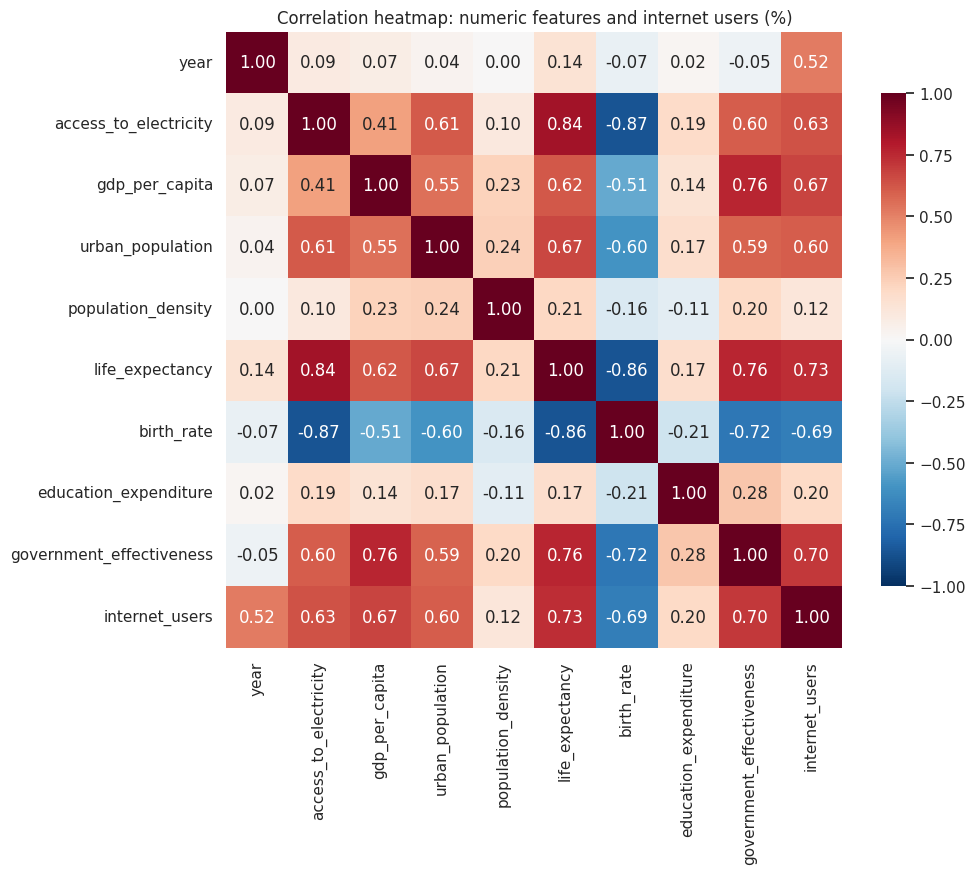

Correlation with internet_users:
life_expectancy             0.735
government_effectiveness    0.703
birth_rate                 -0.694
gdp_per_capita              0.673
access_to_electricity       0.633
urban_population            0.602
year                        0.518
education_expenditure       0.197
population_density          0.124


In [6]:
corr = data[NUMERIC + [TARGET]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation heatmap: numeric features and internet users (%)")
plt.show()
print("Correlation with internet_users:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

**What it shows.** Internet use correlates most with life expectancy (0.73), government effectiveness (0.70), birth rate (−0.69, negative), GDP per capita (0.67), electricity (0.63), urban share (0.60) and year (0.52). Education spending (0.20) and population density (0.12) are weak on their own. Many features are also strongly correlated **with each other**: electricity vs birth rate is −0.87, and life expectancy vs electricity is 0.84.

**What I decided.** (1) I kept only one governance score (government effectiveness), because the other governance scores carry almost the same information. (2) Because of this multicollinearity, I expect the linear models' individual coefficients to be unstable, and I added tree models, which are not affected by it. (3) I kept `education_expenditure` despite its weak *linear* correlation. It is my mission variable, and it may still matter in combination with other features.

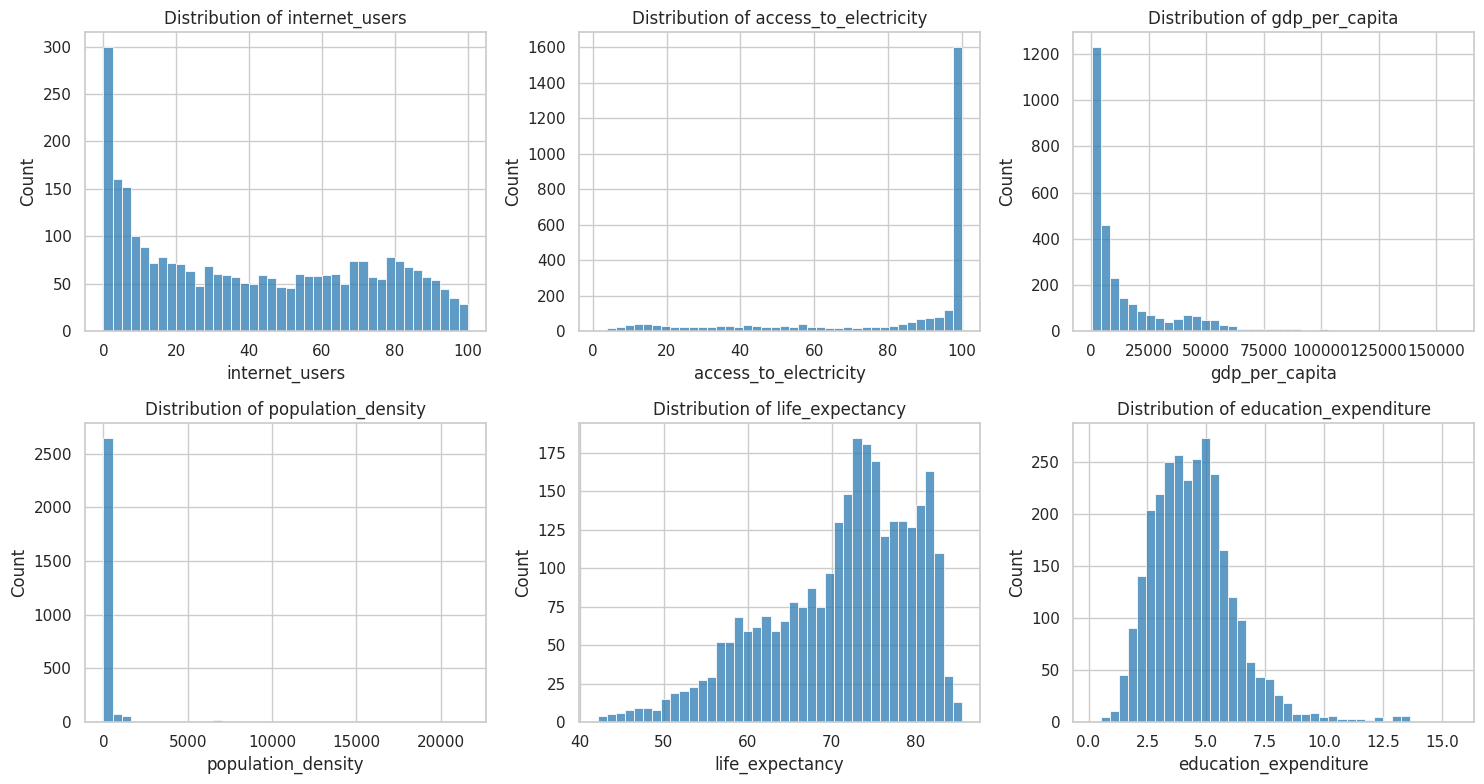

Skewness:
internet_users           0.24
access_to_electricity   -1.41
gdp_per_capita           2.33
population_density       8.77
life_expectancy         -0.75
education_expenditure    1.31


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, [TARGET, "access_to_electricity", "gdp_per_capita",
                               "population_density", "life_expectancy", "education_expenditure"]):
    sns.histplot(data[col], bins=40, ax=ax, color="#2a7ab0")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()
print("Skewness:")
print(data[[TARGET, "access_to_electricity", "gdp_per_capita", "population_density",
            "life_expectancy", "education_expenditure"]].skew().round(2).to_string())

**What it shows.** The target covers the whole 0–100% range, with a large pile near 0%: many country-years had almost no internet users. Electricity is piled up at 100% (skew −1.4). GDP per capita (skew 2.3) and population density (skew 8.8, from places like Macao, Monaco and Singapore) are strongly right-skewed, with extreme values.

**What I decided.** (1) Standardise every numeric feature so that the large-valued columns (GDP is in tens of thousands) do not dominate gradient descent. (2) Keep the extreme values, because they are real countries, not errors. (3) Clip predictions to 0–100%, because the target is a percentage. (4) The skew and the pile-ups suggest relationships that are not straight lines, which is a reason to compare against decision trees and random forests.

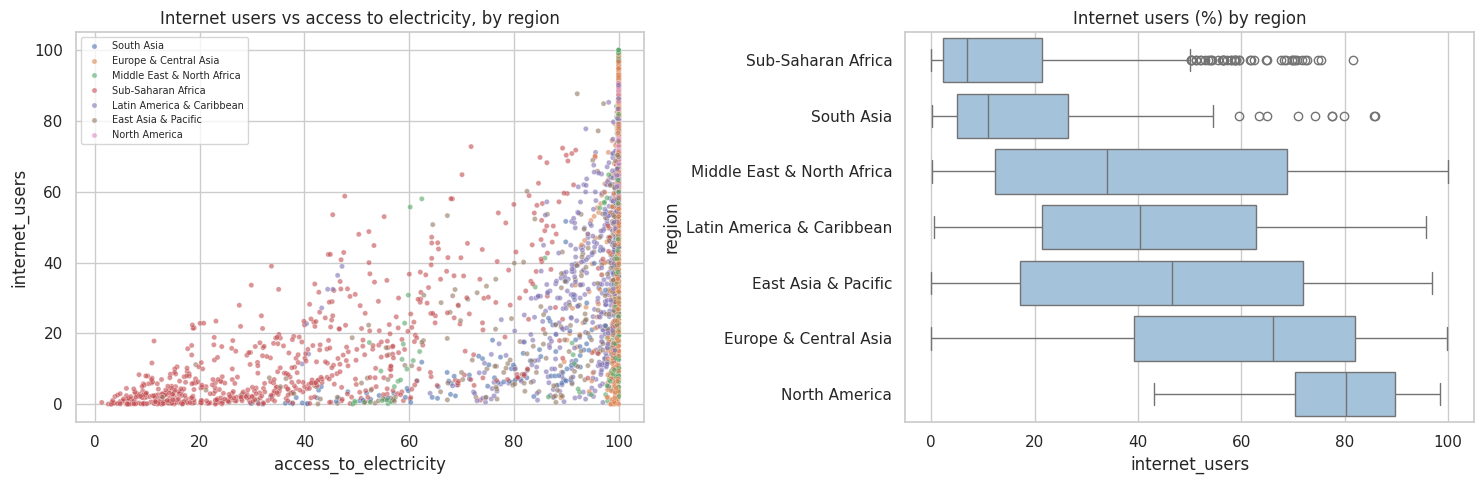

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=data, x="access_to_electricity", y=TARGET, hue="region", s=14, alpha=.6, ax=axes[0])
axes[0].set_title("Internet users vs access to electricity, by region")
axes[0].legend(fontsize=7)
order = data.groupby("region")[TARGET].median().sort_values().index
sns.boxplot(data=data, y="region", x=TARGET, order=order, ax=axes[1], color="#9cc3e4")
axes[1].set_title("Internet users (%) by region")
plt.tight_layout()
plt.show()

**What it shows.** The relationship with electricity is **not a straight line**. Internet use stays near 0% until electricity access is high. At 100% electricity it ranges from 0% to 100%, depending on the year and the country's income. By region, Sub-Saharan Africa has the lowest median (about 7%) and North America the highest (about 80%).

**What I decided.** (1) A straight line will underfit this curved, threshold-like pattern, so I expect the tree-based models to beat linear regression. (2) Region carries real information, so I keep it as a one-hot encoded categorical feature. (3) `year` must stay in the model, because the same electricity level means much higher internet use in 2020 than in 2005.

## 5. Train/test split and standardisation
**Two choices to avoid an over-optimistic test score:**
1. **Split by country, not by row** (`GroupShuffleSplit`). A country's 2015 and 2016 rows are almost identical, so a random row split would let a model "remember" a country it already saw in training. Splitting by country tests the real use case: predicting for a country the model has never seen.
2. **Hold back the most recent complete year (2021) entirely.** The 2021 rows act as "new data that arrives later". I use them in Section 13 and in the API's `/retrain` demo.

I also keep a **validation** group of countries inside the training set, so I can tune hyperparameters without ever looking at the test set.

**Encoding and scaling:** `region` is one-hot encoded (one 0/1 column per region). Numeric features are standardised with `StandardScaler`, which is **fit on the training set only**; inside a `Pipeline` that happens automatically.

In [9]:
model_data = data[data["year"] <= 2020].reset_index(drop=True)
new_data_2021 = data[data["year"] == 2021].reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(model_data, groups=model_data["country"]))
train_df, test_df = model_data.iloc[train_idx], model_data.iloc[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
sub_idx, val_idx = next(gss_val.split(train_df, groups=train_df["country"]))
sub_df, val_df = train_df.iloc[sub_idx], train_df.iloc[val_idx]

X_train, y_train = train_df[FEATURES], train_df[TARGET].values
X_test, y_test = test_df[FEATURES], test_df[TARGET].values
print(f"Train: {len(train_df)} rows from {train_df.country.nunique()} countries")
print(f"Test:  {len(test_df)} rows from {test_df.country.nunique()} countries (never seen in training)")
print(f"  (inside train) tuning-fit: {len(sub_df)} rows, validation: {len(val_df)} rows")
print(f"New 2021 data held back: {len(new_data_2021)} rows")
print("South Sudan is in the", "TEST" if "South Sudan" in set(test_df.country) else "TRAIN", "set")

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

pre = make_preprocessor().fit(X_train)        # fit on TRAIN only
X_train_s, X_test_s = pre.transform(X_train), pre.transform(X_test)
print("Model input columns after encoding:", X_train_s.shape[1])
print("Train means after scaling (should be ~0):", X_train_s[:, :len(NUMERIC)].mean(axis=0).round(2))

Train: 2153 rows from 149 countries
Test:  572 rows from 38 countries (never seen in training)
  (inside train) tuning-fit: 1735 rows, validation: 418 rows
New 2021 data held back: 137 rows
South Sudan is in the TEST set
Model input columns after encoding: 16
Train means after scaling (should be ~0): [ 0.  0.  0. -0.  0.  0. -0. -0.  0.]


## 6. Model 1: linear regression by gradient descent (`SGDRegressor`)
scikit-learn does not record a loss history, so I train with `partial_fit` in a loop. Each call is one **epoch** (one pass over the shuffled training data), and I record the MSE after every epoch.

**Tuning** on the validation countries (score = validation MSE averaged over the last 5 epochs, so the choice rewards a *stable* fit):
* `eta0`: the learning rate (step size)
* `alpha`: L2 regularisation strength (a penalty on large weights)
* number of epochs

In [10]:
def train_sgd(X_fit, y_fit, eta0, alpha, epochs, X_eval=None, y_eval=None, seed=RANDOM_STATE):
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    fit_hist, eval_hist = [], []
    for _ in range(epochs):
        order = rng.permutation(len(y_fit))
        sgd.partial_fit(X_fit[order], y_fit[order])
        fit_hist.append(mean_squared_error(y_fit, sgd.predict(X_fit)))
        if X_eval is not None:
            eval_hist.append(mean_squared_error(y_eval, sgd.predict(X_eval)))
    return sgd, fit_hist, eval_hist

pre_tune = make_preprocessor().fit(sub_df[FEATURES])
Xs_sub, Xs_val = pre_tune.transform(sub_df[FEATURES]), pre_tune.transform(val_df[FEATURES])
ys_sub, ys_val = sub_df[TARGET].values, val_df[TARGET].values

ETAS, ALPHAS, EPOCH_OPTIONS = [0.00001, 0.0001, 0.001, 0.01, 0.05], [0.0001, 0.001, 0.01, 0.1], [10, 25, 50, 100, 200, 300]
rows = []
for eta0 in ETAS:
    for alpha in ALPHAS:
        _, _, val_hist = train_sgd(Xs_sub, ys_sub, eta0, alpha, max(EPOCH_OPTIONS), Xs_val, ys_val)
        for ep in EPOCH_OPTIONS:
            # average of the last 5 epochs, so a lucky single epoch of a noisy run does not win
            rows.append({"eta0": eta0, "alpha": alpha, "epochs": ep, "val_mse": np.mean(val_hist[ep - 5:ep])})
tuning = pd.DataFrame(rows)
best_sgd_params = tuning.loc[tuning["val_mse"].idxmin()]
print("Best SGD setting on validation countries:")
print(best_sgd_params.to_string())

Best SGD setting on validation countries:
eta0         0.000100
alpha        0.000100
epochs     300.000000
val_mse     97.051581


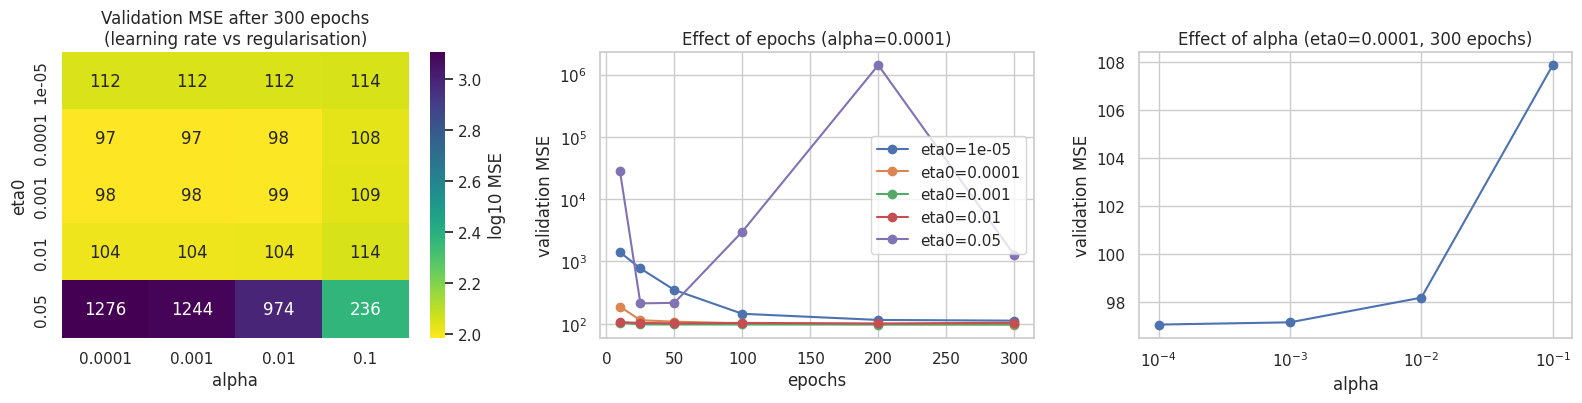

alpha,0.0001,0.0010,0.0100,0.1000
eta0,,,,
0.00001,112.3,112.3,112.2,113.8
0.00010,97.1,97.1,98.2,107.9
0.00100,97.6,97.7,98.7,108.8
0.01000,103.7,103.7,104.4,113.5
0.05000,1275.9,1243.8,973.7,235.8


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
pv = tuning[tuning.epochs == 300].pivot(index="eta0", columns="alpha", values="val_mse")
sns.heatmap(np.log10(pv), annot=pv.round(0), fmt=".0f", cmap="viridis_r", ax=axes[0], cbar_kws={"label": "log10 MSE"})
axes[0].set_title("Validation MSE after 300 epochs\n(learning rate vs regularisation)")
for eta0 in ETAS:
    t = tuning[(tuning.eta0 == eta0) & (tuning.alpha == best_sgd_params.alpha)]
    axes[1].plot(t.epochs, t.val_mse, marker="o", label=f"eta0={eta0}")
axes[1].set_title(f"Effect of epochs (alpha={best_sgd_params.alpha})"); axes[1].set_xlabel("epochs")
axes[1].set_ylabel("validation MSE"); axes[1].legend(); axes[1].set_yscale("log")
t = tuning[(tuning.eta0 == best_sgd_params.eta0) & (tuning.epochs == 300)]
axes[2].plot(t.alpha, t.val_mse, marker="o"); axes[2].set_xscale("log")
axes[2].set_title(f"Effect of alpha (eta0={best_sgd_params.eta0}, 300 epochs)")
axes[2].set_xlabel("alpha"); axes[2].set_ylabel("validation MSE")
plt.tight_layout(); plt.show()
display(pv.round(1))

**How each hyperparameter changed the loss**
* **Learning rate (`eta0`).** At 0.05 the steps overshoot and the model **diverges**: the MSE jumps into the thousands and even past 10⁶ at one point. At 0.00001 learning is too slow, and the MSE is still 112 after 300 epochs. Values of 0.0001 and 0.001 give the lowest validation MSE (about 97). 0.01 converges but bounces around (about 104).
* **Regularisation (`alpha`).** Between 0.0001 and 0.01 there is almost no effect. At 0.1 the validation MSE rises to about 108, because too strong a penalty shrinks useful weights and the model underfits. A linear model on 16 inputs is not overfitting here, so little regularisation is needed.
* **Epochs.** With `eta0=0.0001` most of the improvement happens in the first 25 epochs. After that the curve flattens and slowly improves up to 300.

**Chosen:** `eta0=0.0001`, `alpha=0.0001`, 300 epochs.

### Loss curve: train and test MSE per epoch (best SGD setting)

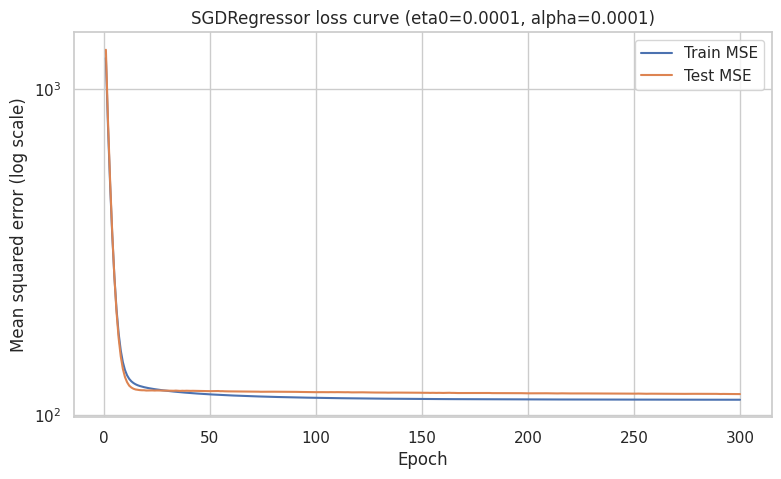

Final train MSE: 111.28 | final test MSE: 115.82


In [12]:
EPOCHS = int(best_sgd_params.epochs)
sgd_model, train_hist, test_hist = train_sgd(X_train_s, y_train, best_sgd_params.eta0,
                                             best_sgd_params.alpha, EPOCHS, X_test_s, y_test)
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), train_hist, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), test_hist, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("Mean squared error (log scale)"); plt.yscale("log")
plt.title(f"SGDRegressor loss curve (eta0={best_sgd_params.eta0}, alpha={best_sgd_params.alpha})")
plt.legend(); plt.show()
print(f"Final train MSE: {train_hist[-1]:.2f} | final test MSE: {test_hist[-1]:.2f}")

**What the loss curve shows.** Both curves fall from about 1,300 to about 120 within roughly 20 epochs, then flatten. Train and test MSE stay very close (about 111 vs 116), so the model is **not overfitting**. The plateau at about 110 is the limit of a *straight-line* model on this curved data (underfitting, also called bias). More epochs would not help; a more flexible model would.

## 7. Models 2 to 4: closed-form linear regression, decision tree, random forest

In [13]:
lin_model = LinearRegression().fit(X_train_s, y_train)

# light tuning of the tree models on the validation countries (never on the test set)
def val_mse(model):
    model.fit(Xs_sub, ys_sub)
    return mean_squared_error(ys_val, model.predict(Xs_val))

tree_scores = {d: val_mse(DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=RANDOM_STATE))
               for d in [3, 5, 8, 12, None]}
best_depth = min(tree_scores, key=tree_scores.get)
print("Decision tree validation MSE by max_depth:", {k: round(v, 1) for k, v in tree_scores.items()})

rf_scores = {}
for depth in [8, 12, 16]:
    for leaf in [1, 3, 5]:
        rf_scores[(depth, leaf)] = val_mse(RandomForestRegressor(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf, n_jobs=-1, random_state=RANDOM_STATE))
best_rf = min(rf_scores, key=rf_scores.get)
print("Random forest best (max_depth, min_samples_leaf):", best_rf, "val MSE", round(rf_scores[best_rf], 1))

tree_model = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5,
                                   random_state=RANDOM_STATE).fit(X_train_s, y_train)
rf_model = RandomForestRegressor(n_estimators=200, max_depth=best_rf[0], min_samples_leaf=best_rf[1],
                                 n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_s, y_train)

Decision tree validation MSE by max_depth: {3: 156.5, 5: 116.2, 8: 88.0, 12: 91.6, None: 90.5}
Random forest best (max_depth, min_samples_leaf): (16, 5) val MSE 55.0


## 8. Comparison of all four models on the same test set

,Model,Train MSE,Test MSE,Test RMSE (% points),Test R²
0,Random forest,14.489,70.884,8.419,0.935
1,Decision tree,28.665,110.843,10.528,0.898
2,Linear regression (closed form),110.902,115.486,10.746,0.894
3,"Linear regression (SGD, gradient descent)",111.279,115.821,10.762,0.894


Best model (lowest test MSE): Random forest with test MSE 70.88


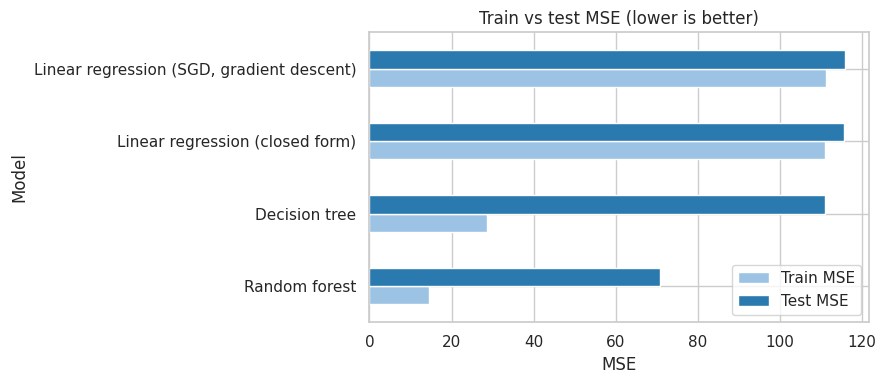

In [14]:
models = {
    "Linear regression (SGD, gradient descent)": sgd_model,
    "Linear regression (closed form)": lin_model,
    "Decision tree": tree_model,
    "Random forest": rf_model,
}
results = []
for name, m in models.items():
    p_tr, p_te = m.predict(X_train_s), m.predict(X_test_s)
    results.append({"Model": name,
                    "Train MSE": mean_squared_error(y_train, p_tr),
                    "Test MSE": mean_squared_error(y_test, p_te),
                    "Test RMSE (% points)": np.sqrt(mean_squared_error(y_test, p_te)),
                    "Test R²": r2_score(y_test, p_te)})
results = pd.DataFrame(results).sort_values("Test MSE").reset_index(drop=True)
display(results.round(3))
best_name = results.loc[0, "Model"]
print(f"Best model (lowest test MSE): {best_name} with test MSE {results.loc[0, 'Test MSE']:.2f}")

plt.figure(figsize=(9, 4))
r = results.set_index("Model")[["Train MSE", "Test MSE"]]
r.plot(kind="barh", ax=plt.gca(), color=["#9cc3e4", "#2a7ab0"])
plt.title("Train vs test MSE (lower is better)"); plt.xlabel("MSE"); plt.tight_layout(); plt.show()

**Best model: random forest** (lowest test MSE, **70.9**; RMSE about 8.4 percentage points; R² 0.935). It is the model I save.

**How the dataset affected each model**
* **The two linear regressions** (closed form 115.5, SGD 115.8) are almost identical, which confirms that gradient descent converged to the same solution as the exact formula. Both are limited by the curved, threshold-like relationships seen in the scatter plot.
* **The single decision tree** captures those thresholds, but it **overfits**: train MSE 28.7 vs test MSE 110.8. One tree memorises the training countries.
* **The random forest** averages 200 trees, each built on different random samples. This keeps the tree's ability to model non-linear patterns and interactions (for example, electricity matters more in later years) while cancelling out most of the overfitting. It still fits training data better than test data (14.5 vs 70.9), but it is clearly the best on **countries it has never seen**, which is the real use case.

### Which features matter most?

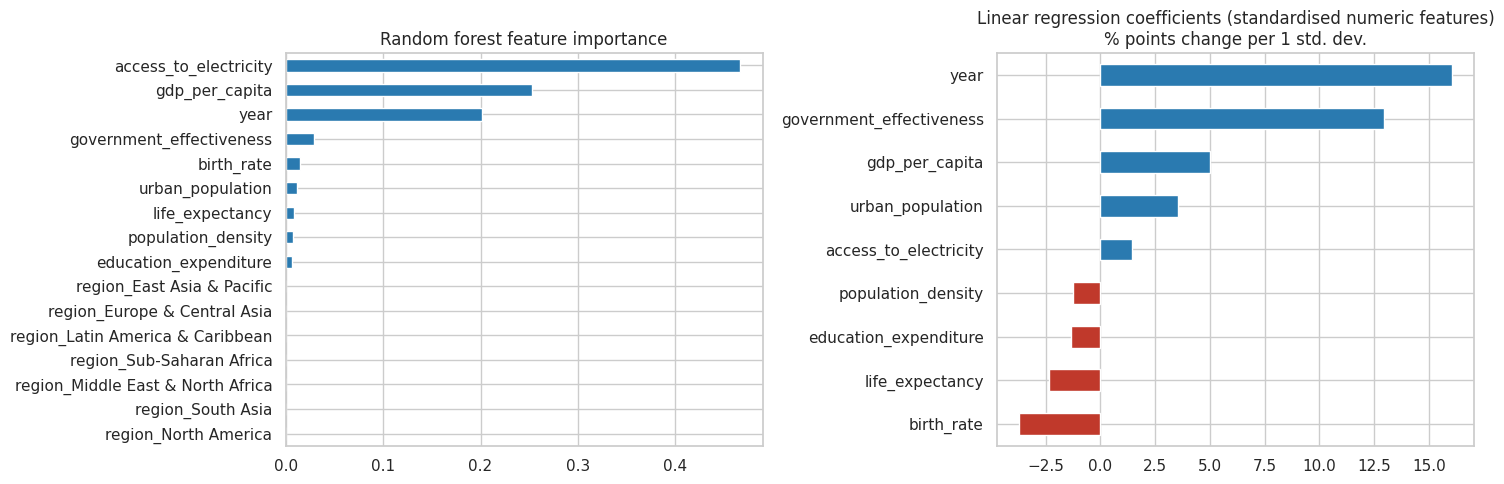

access_to_electricity                0.466
gdp_per_capita                       0.253
year                                 0.201
government_effectiveness             0.029
birth_rate                           0.015
urban_population                     0.011
life_expectancy                      0.009
population_density                   0.008
education_expenditure                0.007
region_East Asia & Pacific           0.000
region_Europe & Central Asia         0.000
region_Latin America & Caribbean     0.000
region_Sub-Saharan Africa            0.000
region_Middle East & North Africa    0.000
region_South Asia                    0.000
region_North America                 0.000


In [15]:
feat_names = NUMERIC + list(pre.named_transformers_["cat"].get_feature_names_out(CATEGORICAL))
importance = pd.Series(rf_model.feature_importances_, index=feat_names).sort_values()
lin_coef = pd.Series(lin_model.coef_[:len(NUMERIC)], index=NUMERIC).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.plot(kind="barh", ax=axes[0], color="#2a7ab0"); axes[0].set_title("Random forest feature importance")
lin_coef.plot(kind="barh", ax=axes[1], color=np.where(lin_coef > 0, "#2a7ab0", "#c0392b"))
axes[1].set_title("Linear regression coefficients (standardised numeric features)\n% points change per 1 std. dev.")
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round(3).to_string())

**What matters most.** In the random forest, **access to electricity (0.47)**, **GDP per capita (0.25)** and **year (0.20)** account for over 90% of the importance. For a ministry or NGO, the message is that electricity is the biggest lever: digital-education plans in places without power will not reach people. Region gets almost zero importance, because the other features already explain the regional differences.

The linear coefficients tell a different story, and some signs look wrong (life expectancy and education spending come out negative). This is the multicollinearity warned about in the heatmap: overlapping features share the effect between them. That is one more reason not to read linear coefficients as causes, and one more reason to prefer the forest.

## 9. Scatter plots: the strongest single feature before and after fitting a line
These two plots use **only one feature**: the one most correlated with the target. I fit a separate one-feature linear regression just to draw the line; the saved model still uses all 10 features.

Feature most correlated with internet_users: life_expectancy (r = 0.73)


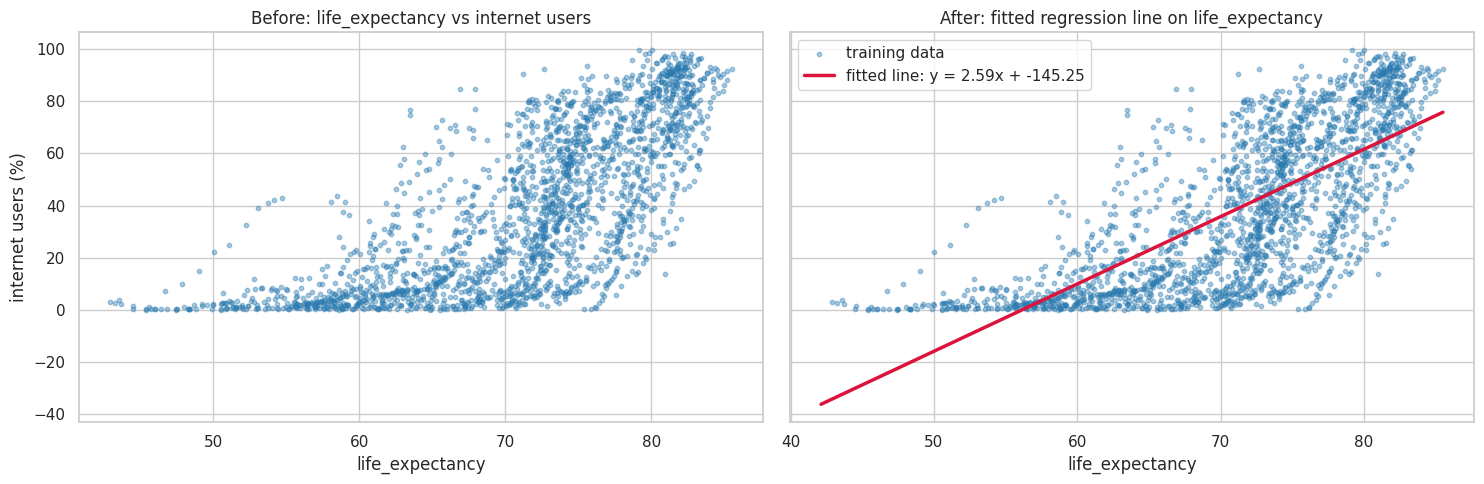

One-feature line test MSE: 427.86


In [16]:
top_feature = corr[TARGET].drop(TARGET).abs().idxmax()
print("Feature most correlated with internet_users:", top_feature,
      f"(r = {corr.loc[top_feature, TARGET]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
axes[0].scatter(train_df[top_feature], y_train, s=10, alpha=.4, color="#2a7ab0")
axes[0].set_title(f"Before: {top_feature} vs internet users")
axes[0].set_xlabel(top_feature); axes[0].set_ylabel("internet users (%)")

one = LinearRegression().fit(train_df[[top_feature]], y_train)
xs = np.linspace(data[top_feature].min(), data[top_feature].max(), 100).reshape(-1, 1)
axes[1].scatter(train_df[top_feature], y_train, s=10, alpha=.4, color="#2a7ab0", label="training data")
axes[1].plot(xs, one.predict(pd.DataFrame(xs, columns=[top_feature])), color="crimson", lw=2.5,
             label=f"fitted line: y = {one.coef_[0]:.2f}x + {one.intercept_:.2f}")
axes[1].set_title(f"After: fitted regression line on {top_feature}")
axes[1].set_xlabel(top_feature); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"One-feature line test MSE: {mean_squared_error(y_test, one.predict(test_df[[top_feature]])):.2f}")

**What it shows.** The single most correlated feature is life expectancy (r = 0.73). The fitted line, internet users ≈ 2.59 × life expectancy − 145.25, says that each extra year of life expectancy goes with about 2.6 more percentage points of internet use. But the cloud is curved: flat below about 65 years, then steep. The line even predicts *negative* internet use below about 56 years. Its test MSE (428) is six times worse than the full random forest (70.9). One feature is not enough, which is why the deployed model is multivariate.

## 10. Save the best model with its preprocessing
I wrap the preprocessing and the best model in one scikit-learn `Pipeline`, refit it on the training set, and save it with `joblib` as `best_model.pkl` (it goes in `summative/API/`).

The saved file is a small dictionary holding:
* the pipeline
* the feature lists
* the **training rows**, which the API needs so `/retrain` can refit on *original + new* data (the assignment's rule for non-SGD models)

In [17]:
estimators = {
    "Linear regression (SGD, gradient descent)": SGDRegressor(
        learning_rate="constant", eta0=best_sgd_params.eta0, alpha=best_sgd_params.alpha,
        max_iter=EPOCHS, tol=None, random_state=RANDOM_STATE),
    "Linear regression (closed form)": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(n_estimators=200, max_depth=best_rf[0], min_samples_leaf=best_rf[1],
                                           n_jobs=-1, random_state=RANDOM_STATE),
}
best_pipeline = Pipeline([("preprocess", make_preprocessor()), ("model", estimators[best_name])])
best_pipeline.fit(X_train, y_train)
pipe_test_mse = mean_squared_error(y_test, best_pipeline.predict(X_test))
print(f"Saved pipeline test MSE: {pipe_test_mse:.2f}")

bundle = {
    "pipeline": best_pipeline,
    "model_name": best_name,
    "features": FEATURES, "numeric": NUMERIC, "categorical": CATEGORICAL, "target": TARGET,
    "regions": sorted(REGIONS),
    "train_data": train_df[FEATURES + [TARGET]].to_dict(orient="list"),
    "test_mse": pipe_test_mse,
}
MODEL_PATH = "best_model.pkl"
joblib.dump(bundle, MODEL_PATH, compress=3)
print("Saved", MODEL_PATH, round(os.path.getsize(MODEL_PATH) / 1e6, 2), "MB")

Saved pipeline test MSE: 70.88
Saved best_model.pkl 2.37 MB


## 11. Load the saved model and predict one row of the test set
The API (`summative/API/prediction.py`) reuses this same function.

In [18]:
def predict_internet_users(row, model_path="best_model.pkl"):
    # Load the saved pipeline and predict % of population using the internet for ONE row (dict or Series).
    saved = joblib.load(model_path)
    X = pd.DataFrame([{f: row[f] for f in saved["features"]}])
    return float(np.clip(saved["pipeline"].predict(X)[0], 0, 100))

sample = test_df.iloc[0]
pred = predict_internet_users(sample)
print("Country/year:", sample["country"], int(sample["year"]))
display(sample[FEATURES].to_frame("input value"))
print(f"Predicted internet users: {pred:.1f}%  |  actual: {sample[TARGET]:.1f}%")

Country/year: Argentina 2000


,input value
year,2000
access_to_electricity,95.680473
gdp_per_capita,7666.517834
urban_population,89.141999
population_density,13.545843
life_expectancy,73.926
birth_rate,19.366
education_expenditure,4.58031
government_effectiveness,-0.028039
region,Latin America & Caribbean


Predicted internet users: 17.4%  |  actual: 7.0%


In [19]:
# The mission country: South Sudan's rows from the test/train data
ss = model_data[model_data["country"] == "South Sudan"]
if len(ss):
    ss_pred = [predict_internet_users(r) for _, r in ss.iterrows()]
    display(pd.DataFrame({"year": ss["year"].values, "actual %": ss[TARGET].round(1).values,
                          "predicted %": np.round(ss_pred, 1)}))
else:
    print("South Sudan has no complete rows after cleaning.")

,year,actual %,predicted %
0,2013,2.2,5.8
1,2014,2.6,8.4
2,2015,3.0,13.4


**South Sudan.** South Sudan was in the **test** set, so the model never saw it during training. It over-predicts: about 6–13% predicted vs 2–3% actual. South Sudan's real internet use is even lower than its electricity, income and other indicators would suggest. Likely reasons, which are not in the data, include conflict, the high price of data and few towers outside the main towns. For conflict-affected countries, a planner should treat the prediction as an **upper bound**. This is the access gap my mission is about.

## 12. East Africa focus: does the model work for the region it is built for?
To check the model honestly for East Africa, I retrain the same random forest on all countries **except** the East African ones. Then I predict every East African country. The model has never seen any of them, so this shows how it would perform for a ministry in the region.

In [20]:
EAST_AFRICA = ["South Sudan", "Kenya", "Uganda", "Tanzania", "Rwanda", "Burundi", "Ethiopia",
               "Somalia", "Sudan", "Djibouti", "Eritrea", "Congo, Dem. Rep."]
print("Complete East African rows:", data["country"].isin(EAST_AFRICA).sum(), "of", len(data))

ea_train = model_data[~model_data["country"].isin(EAST_AFRICA)]
ea_test = model_data[model_data["country"].isin(EAST_AFRICA)].copy()

ea_pipeline = Pipeline([("preprocess", make_preprocessor()),
                        ("model", RandomForestRegressor(n_estimators=200, max_depth=best_rf[0],
                                                        min_samples_leaf=best_rf[1], n_jobs=-1,
                                                        random_state=RANDOM_STATE))])
ea_pipeline.fit(ea_train[FEATURES], ea_train[TARGET])
ea_test["predicted"] = np.clip(ea_pipeline.predict(ea_test[FEATURES]), 0, 100)

ea_mse = mean_squared_error(ea_test[TARGET], ea_test["predicted"])
print(f"East Africa (never seen in training): MSE {ea_mse:.1f}, typical error {np.sqrt(ea_mse):.1f} percentage points")

per_country = (ea_test.groupby("country")
               .apply(lambda d: pd.Series({"rows": len(d),
                                           "MSE": mean_squared_error(d[TARGET], d["predicted"]),
                                           "mean actual %": d[TARGET].mean(),
                                           "mean predicted %": d["predicted"].mean()}))
               .sort_values("MSE").round(1))
display(per_country)

Complete East African rows: 134 of 2862
East Africa (never seen in training): MSE 31.7, typical error 5.6 percentage points


,rows,MSE,mean actual %,mean predicted %
country,,,,
Eritrea,1.0,0.1,0.2,0.5
Sudan,4.0,0.2,0.6,1.0
Tanzania,17.0,1.8,7.6,8.2
Rwanda,14.0,5.9,11.3,9.4
Burundi,17.0,11.2,1.5,4.1
"Congo, Dem. Rep.",7.0,15.3,6.8,8.0
Ethiopia,17.0,18.3,6.6,8.8
South Sudan,3.0,19.5,2.6,6.5
Kenya,18.0,50.7,10.8,12.9


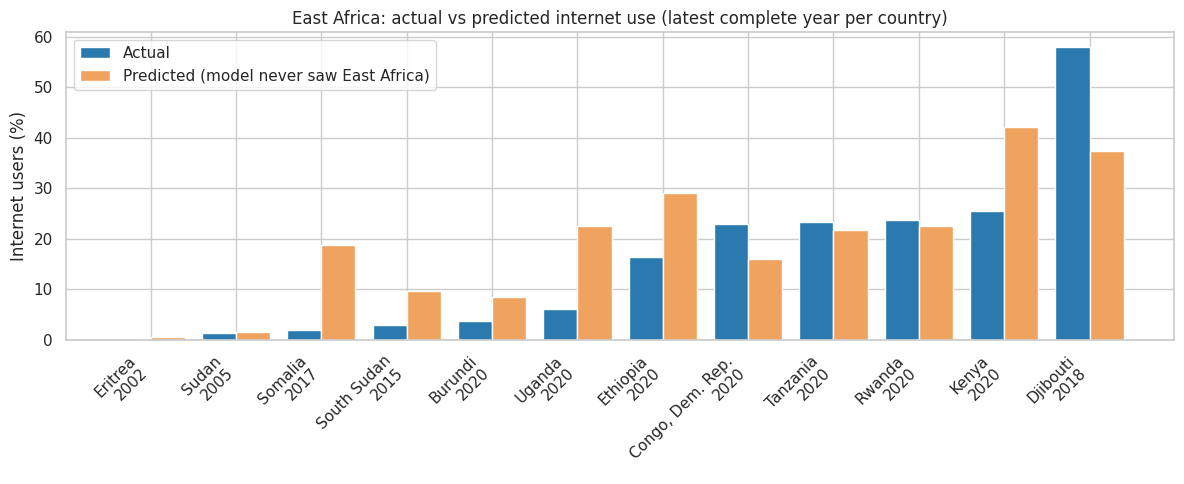

,country,year,internet_users,predicted,gap (predicted - actual)
831,Eritrea,2002,0.2,0.5,0.3
2381,Sudan,2005,1.3,1.6,0.3
2289,Somalia,2017,2.0,18.9,16.9
2312,South Sudan,2015,3.0,9.7,6.7
430,Burundi,2020,3.8,8.6,4.8
2573,Uganda,2020,6.1,22.6,16.5
887,Ethiopia,2020,16.4,29.1,12.7
601,"Congo, Dem. Rep.",2020,22.9,16.0,-6.9
2465,Tanzania,2020,23.4,21.8,-1.7
2121,Rwanda,2020,23.8,22.6,-1.2


In [21]:
latest = ea_test.loc[ea_test.groupby("country")["year"].idxmax()].sort_values(TARGET)
x = np.arange(len(latest))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, latest[TARGET], width=0.4, label="Actual", color="#2a7ab0")
plt.bar(x + 0.2, latest["predicted"], width=0.4, label="Predicted (model never saw East Africa)", color="#f0a35e")
plt.xticks(x, [f"{c}\n{y}" for c, y in zip(latest["country"], latest["year"])], rotation=45, ha="right")
plt.ylabel("Internet users (%)")
plt.title("East Africa: actual vs predicted internet use (latest complete year per country)")
plt.legend(); plt.tight_layout(); plt.show()

latest["gap (predicted - actual)"] = (latest["predicted"] - latest[TARGET]).round(1)
display(latest[["country", "year", TARGET, "predicted", "gap (predicted - actual)"]].round(1))

**What it shows.** Without seeing a single East African country, the model's typical error on the region is about **5.6 percentage points** (MSE about 32). That is lower than on the global test set, because East African values are mostly between 0% and 25%.
* **Well predicted:** Tanzania, Rwanda and Sudan are within about 1–2 points.
* **Over-predicted:** Uganda (predicted about 23% vs actual 6% in 2020), Kenya (about 42% vs 26%), Ethiopia and South Sudan (about 10% vs 3%).

**Why this matters for my mission.** A large positive gap means the country already has the electricity, income and urbanisation that usually come with much higher internet use, yet people are not online. The barrier is then something the data does not measure: the price of data, digital literacy, device cost or conflict. Those countries, South Sudan and Uganda first, are where **digital-literacy and affordable-access programmes** should go before money is spent on online-only education services.

## 13. New data: the held-back 2021 rows
I save the 2021 rows, which the model has never seen, as `new_data_2021.csv`. They use the **same columns as the training data**, so this is the file to upload to the API's `/retrain` endpoint in Swagger.

In [22]:
new_data_2021[FEATURES + [TARGET]].to_csv("new_data_2021.csv", index=False)
before = mean_squared_error(new_data_2021[TARGET], best_pipeline.predict(new_data_2021[FEATURES]))
print(f"{len(new_data_2021)} rows saved. Current model MSE on these 2021 rows: {before:.2f}")

137 rows saved. Current model MSE on these 2021 rows: 89.23


The current model does worse on 2021 (MSE about 89) than on the test set (about 71). Tree models cannot **extrapolate**: they have never seen a year after 2020, so they cannot continue the upward trend. This is exactly why the API has a `/retrain` endpoint. When the World Bank publishes a new year, uploading it refits the forest on the original data plus the new rows, and the next `/predict` call uses the updated model.

## 14. Conclusion: is the loss high or low, and how could it be reduced?
* **Test MSE 70.9, so the typical error is about 8.4 percentage points** on a 0–100 scale, with R² 0.935. On East Africa alone, which the model never saw, the typical error is about 5.6 points. For the main decision (should a learning service be online or offline in this country?), this is accurate enough: telling 10% from 60% is easy. For a country near 3%, like South Sudan, an 8-point error is large in relative terms, so predictions there should be read as upper bounds.
* **Ways to reduce it:**
  1. Add direct access features: mobile subscriptions, mobile network coverage, and the price of 1 GB of data relative to income.
  2. Add last year's internet use as a feature (a lag feature), since internet use changes gradually.
  3. Log-transform the skewed GDP per capita and population density.
  4. Try gradient boosting.
  5. Retrain every year as new data arrives.

In [23]:
files.download("best_model.pkl")      # -> summative/API/best_model.pkl
files.download("new_data_2021.csv")   # -> summative/linear_regression/new_data_2021.csv

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>